In [ ]:
!pip install numpy opencv-python scikit-image scipy matplotlib pandas

### Etapa 1: Configurações

In [2]:
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

SEED = 42 

# Caminhos relativos à pasta do notebook
DIR_DADOS  = Path("imagens/crop-rows-sugar-cane-lapixUFSC")
ARQ_IMG    = DIR_DADOS / "sugarcane1.png"
ARQ_GT     = DIR_DADOS / "sugarcane1-GT.png"
DIR_RESULT = Path("resultados")
DIR_RESULT.mkdir(exist_ok=True)


CFG = {
    "gsd_m": 0.05,        # tamanho do pixel no solo (m/pixel), ~5 cm segundo a LAPIX
    "tam_bloco": 512,     # lado do bloco em pixels (512 px ≈ 25,6 m ≈ 17 linhas de cana)
    "margem_borda": 100,  # px descartados junto à borda do talhão (carreador)
    "frac_ajuste": 0.3,   # fração dos blocos usada para ajustar parâmetros
}

plt.rcParams["figure.dpi"] = 110

### Etapa 2: Leitura de dados

Imagem: (6595, 9391, 3), dtype=uint8
Talhão: 46.1% da imagem
Vegetação dentro do talhão: 34.5%


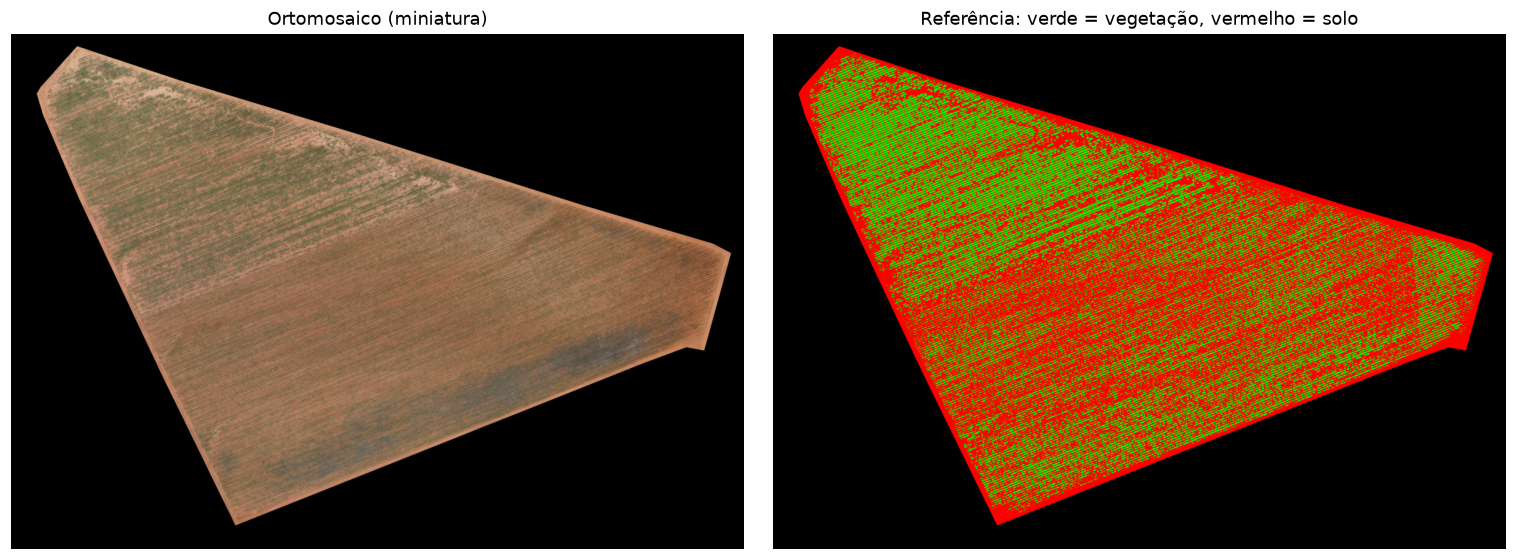

In [ ]:
def ler_imagem_rgb(caminho):
    """Lê uma imagem e devolve em RGB (uint8).

    O cv2.imread falha em caminhos com acento no Windows ("Projeto Prático"),
    por isso lemos os bytes com NumPy e decodificamos com cv2.imdecode.
    O OpenCV trabalha em BGR; convertemos para RGB logo na leitura para
    evitar confusão de canais no resto do pipeline.
    """
    dados = np.fromfile(str(caminho), dtype=np.uint8)
    img = cv2.imdecode(dados, cv2.IMREAD_COLOR)  # IMREAD_COLOR descarta o canal alfa (transparência)
    if img is None:
        raise FileNotFoundError(f"Não foi possível ler {caminho}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img = ler_imagem_rgb(ARQ_IMG)
gt  = ler_imagem_rgb(ARQ_GT)

# A referência usa cores puras: verde = vegetação, vermelho = solo, preto = fora do talhão
R, G, B = gt[..., 0], gt[..., 1], gt[..., 2]
# Máscaras para binarizar
mask_veg    = (G == 255) & (R == 0) # Apenas verde
mask_solo   = (R == 255) & (G == 0) # Apenas vermelho
mask_talhao = mask_veg | mask_solo

print(f"Imagem: {img.shape}, dtype={img.dtype}")
print(f"Talhão: {mask_talhao.mean():.1%} da imagem")
print(f"Vegetação dentro do talhão: {mask_veg.sum() / mask_talhao.sum():.1%}")

# Reduz para 1200px de largura, apenas para visualização
def miniatura(arr, largura=1200):
    """Reduz a imagem só para visualização (o mosaico tem ~62 milhões de pixels)."""
    esc = largura / arr.shape[1]
    return cv2.resize(arr, None, fx=esc, fy=esc, interpolation=cv2.INTER_AREA), esc

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(miniatura(img)[0]); ax[0].set_title("Ortomosaico (miniatura)")
ax[1].imshow(miniatura(gt)[0]);  ax[1].set_title("Referência: verde = vegetação, vermelho = solo")
for a in ax:
    a.axis("off")
plt.tight_layout(); plt.show()

### Etapa 3: Divisão em blocos

conjunto
teste     50
ajuste    21
Name: count, dtype: int64


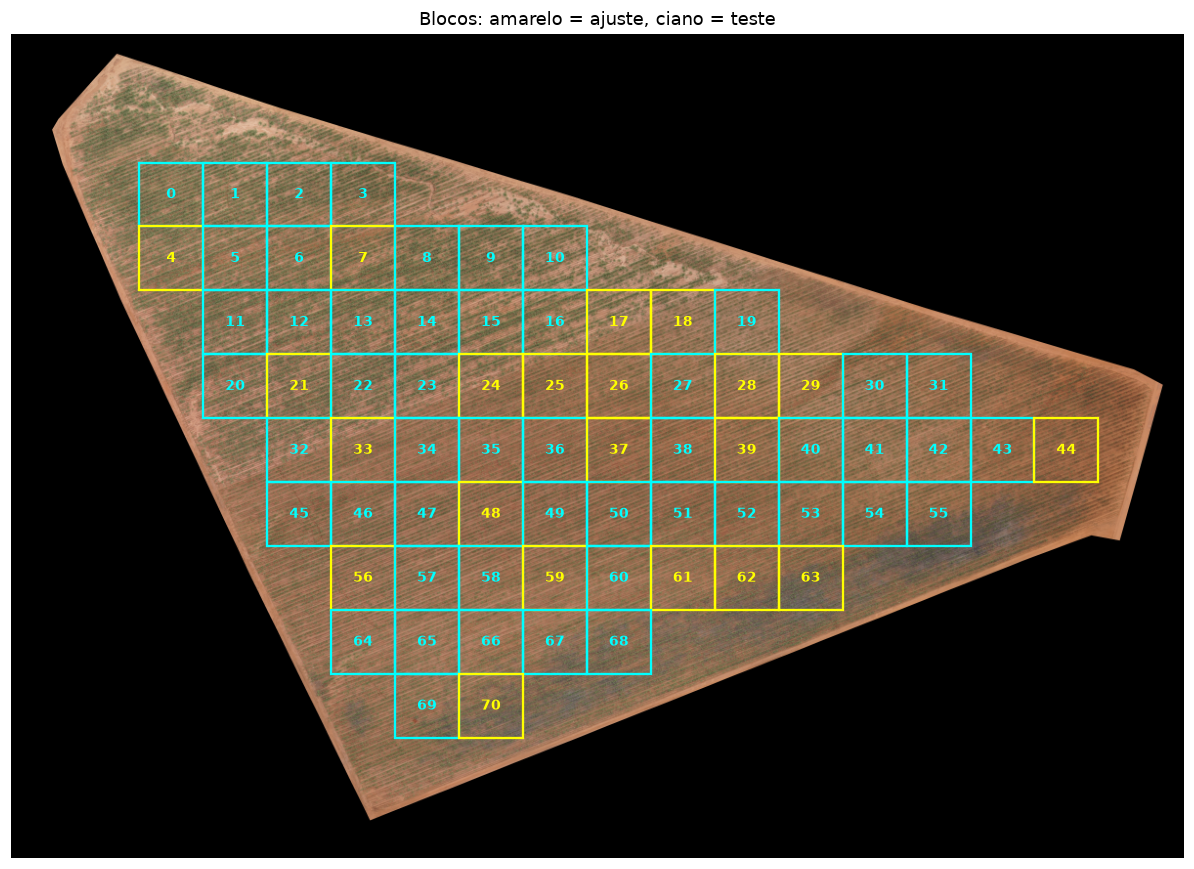

In [ ]:
def gerar_blocos(mask_talhao, tam, margem):
    """Grade regular de blocos tam x tam inteiramente dentro do talhão.

    A máscara é erodida antes (morfologia!) para afastar os blocos da borda,
    onde há o carreador e o efeito de borda do mosaico.

    Retorna as coordenadas de cada bloco em tuplas (y,x). Canto superior esquerdo de blocos.
    """
    k = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * margem + 1, 2 * margem + 1))
    talhao_interno = cv2.erode(mask_talhao.astype(np.uint8), k).astype(bool)

    H, W = mask_talhao.shape
    blocos = []
    for y in range(0, H - tam + 1, tam):
        for x in range(0, W - tam + 1, tam):
            if talhao_interno[y:y + tam, x:x + tam].all():
                blocos.append((y, x))
    return blocos

def recortar(arr, bloco, tam=CFG["tam_bloco"]):
    y, x = bloco
    return arr[y:y + tam, x:x + tam]

blocos = gerar_blocos(mask_talhao, CFG["tam_bloco"], CFG["margem_borda"])

# Sorteio reprodutível: parte dos blocos para AJUSTAR parâmetros, o resto para TESTAR
rng = np.random.default_rng(SEED)
ordem = rng.permutation(len(blocos))
n_ajuste = int(round(CFG["frac_ajuste"] * len(blocos)))

df_blocos = pd.DataFrame(blocos, columns=["y", "x"])
df_blocos["conjunto"] = "teste"
df_blocos.loc[ordem[:n_ajuste], "conjunto"] = "ajuste"
df_blocos.index.name = "id"
df_blocos.to_csv(DIR_RESULT / "blocos.csv")
print(df_blocos["conjunto"].value_counts())

# Mapa dos blocos sobre o mosaico
mini, esc = miniatura(img)
t = CFG["tam_bloco"] * esc
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(mini)
for i, (y, x, conj) in df_blocos.iterrows():
    cor = "yellow" if conj == "ajuste" else "cyan"
    ax.add_patch(plt.Rectangle((x * esc, y * esc), t, t, fill=False, ec=cor, lw=1.5))
    ax.text(x * esc + t / 2, y * esc + t / 2, str(i), color=cor,
            ha="center", va="center", fontsize=9, weight="bold")
ax.set_title("Blocos: amarelo = ajuste, ciano = teste"); ax.axis("off")
plt.tight_layout(); plt.show()

In [10]:
blocos[0]

(1024, 1024)

### Etapa 4: Índices de vegetação por cor

In [6]:
def coordenadas_cromaticas(rgb):
    """r, g, b normalizados: cada canal dividido por R+G+B (remove a intensidade)."""
    rgb = rgb.astype(np.float32)
    soma = rgb.sum(axis=2, keepdims=True)
    soma[soma == 0] = 1.0  # evita divisão por zero em pixels pretos
    n = rgb / soma
    return n[..., 0], n[..., 1], n[..., 2]

def indice_exg(rgb):
    """Excess Green (Woebbecke et al., 1995): 2g - r - b."""
    r, g, b = coordenadas_cromaticas(rgb)
    return 2 * g - r - b

def indice_exgr(rgb):
    """ExG - ExR (Meyer & Neto, 2008), com ExR = 1,4r - g."""
    r, g, b = coordenadas_cromaticas(rgb)
    exg = 2 * g - r - b
    exr = 1.4 * r - g
    return exg - exr

def indice_menos_a(rgb):
    """-a* do CIE L*a*b* (sinal invertido para a vegetação ficar positiva).

    A entrada é float32 em [0, 1]: assim o OpenCV devolve a* real,
    em vez da versão de 8 bits (arredondada e deslocada de +128).
    """
    lab = cv2.cvtColor(rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2Lab)
    return -lab[..., 1]

INDICES = {"ExG": indice_exg, "ExGR": indice_exgr, "-a*": indice_menos_a}

def separabilidade_fisher(v, m_veg, m_solo):
    """Critério de Fisher: (média1 - média2)² / (var1 + var2). Maior = classes mais separadas."""
    a, b = v[m_veg], v[m_solo]
    return (a.mean() - b.mean()) ** 2 / (a.var() + b.var())

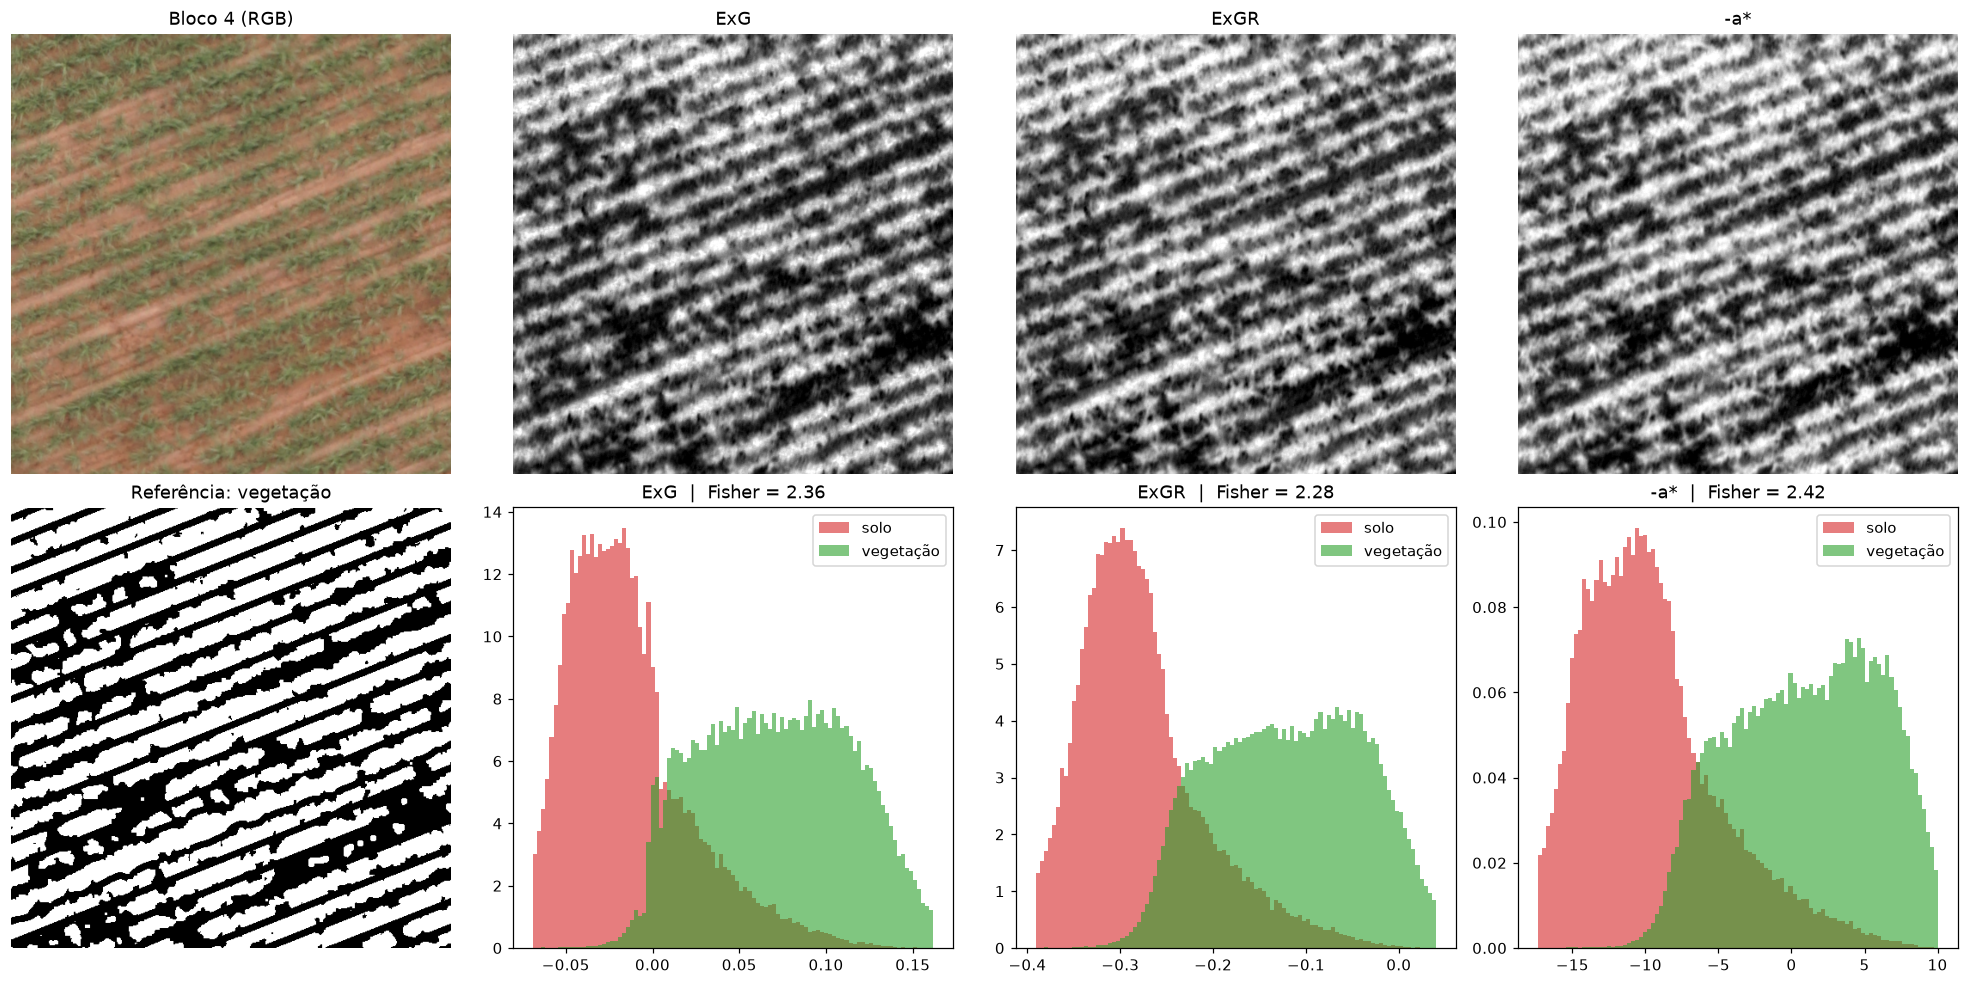

In [7]:
# Visualização em um bloco de ajuste: índice + histograma por classe
id_exemplo = df_blocos.index[df_blocos["conjunto"] == "ajuste"][0]
bloco = tuple(df_blocos.loc[id_exemplo, ["y", "x"]])
rgb_b, veg_b, solo_b = recortar(img, bloco), recortar(mask_veg, bloco), recortar(mask_solo, bloco)

fig, ax = plt.subplots(2, 4, figsize=(18, 9))
ax[0, 0].imshow(rgb_b); ax[0, 0].set_title(f"Bloco {id_exemplo} (RGB)")
ax[1, 0].imshow(veg_b, cmap="gray"); ax[1, 0].set_title("Referência: vegetação")
for j, (nome, f) in enumerate(INDICES.items(), start=1):
    v = f(rgb_b)
    lo, hi = np.percentile(v, [1, 99])
    ax[0, j].imshow(v, cmap="gray", vmin=lo, vmax=hi); ax[0, j].set_title(nome)
    bins = np.linspace(lo, hi, 100)
    ax[1, j].hist(v[solo_b], bins, density=True, alpha=.6, color="tab:red",   label="solo")
    ax[1, j].hist(v[veg_b],  bins, density=True, alpha=.6, color="tab:green", label="vegetação")
    ax[1, j].set_title(f"{nome}  |  Fisher = {separabilidade_fisher(v, veg_b, solo_b):.2f}")
    ax[1, j].legend()
for a in ax[0]:
    a.axis("off")
ax[1, 0].axis("off")
plt.tight_layout(); plt.show()

In [8]:
# Comparação quantitativa dos índices em TODOS os blocos de ajuste
linhas = []
for i in df_blocos.index[df_blocos["conjunto"] == "ajuste"]:
    bl = tuple(df_blocos.loc[i, ["y", "x"]])
    rgb_b, veg_b, solo_b = recortar(img, bl), recortar(mask_veg, bl), recortar(mask_solo, bl)
    for nome, f in INDICES.items():
        linhas.append({"bloco": i, "indice": nome,
                       "fisher": separabilidade_fisher(f(rgb_b), veg_b, solo_b)})

df_fisher = pd.DataFrame(linhas)
tabela = (df_fisher.groupby("indice")["fisher"]
          .agg(["mean", "std", "min", "max"]).round(2)
          .sort_values("mean", ascending=False))
display(tabela)

# Em quantos blocos cada índice foi o melhor?
vencedor = df_fisher.pivot(index="bloco", columns="indice", values="fisher").idxmax(axis=1)
print("Melhor índice por bloco:\n", vencedor.value_counts())

,mean,std,min,max
indice,,,,
-a*,3.80,1.20,1.29,5.50
ExG,3.62,1.02,0.73,5.00
ExGR,3.33,1.04,0.61,4.81


Melhor índice por bloco:
 -a*    18
ExG     3
Name: count, dtype: int64
